In [4]:
import asyncio
import json
import random
import re
from pathlib import Path
import pandas as pd
from playwright.async_api import async_playwright

# Directorios de salida y sesión
DATA_DIR = Path("datos_marketplace")
DATA_DIR.mkdir(exist_ok=True)
SESSION_DIR = Path("fb_session_profile")

FILE_FASE1 = DATA_DIR / "1_candidatos_busqueda.jsonl"
FILE_FASE2 = DATA_DIR / "2_anuncios_detallados.jsonl"
FILE_FASE3 = DATA_DIR / "3_catalogo_vendedores.jsonl"

# Combinaciones de búsqueda basadas en el Anexo del proyecto
BASES = ["jugete", "juguete"]
MODIFICADORES = [
    "", "9", "pegando", "fog", "hechizo", "380", "bruni", 
    "real", "perfo", "pak", "p.a.k", "del 9", "mentiroso", 
    "traumatico", "hecho", "echo", "pepas"
]
QUERIES = [f"{b} {m}".strip() for b in BASES for m in MODIFICADORES]

def guardar_jsonl(filepath: Path, registros: list):
    """Guarda o agrega diccionarios a un archivo JSON Lines."""
    with open(filepath, "a", encoding="utf-8") as f:
        for r in registros:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

def cargar_jsonl(filepath: Path) -> list:
    if not filepath.exists():
        return []
    with open(filepath, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def buscar_llave_recursivo(obj, llave_objetivo):
    """Recorre el árbol JSON de GraphQL buscando cualquier coincidencia con llave_objetivo."""
    hallazgos = []
    if isinstance(obj, dict):
        if llave_objetivo in obj and obj[llave_objetivo] is not None:
            hallazgos.append(obj[llave_objetivo])
        for v in obj.values():
            hallazgos.extend(buscar_llave_recursivo(v, llave_objetivo))
    elif isinstance(obj, list):
        for item in obj:
            hallazgos.extend(buscar_llave_recursivo(item, llave_objetivo))
    return hallazgos

print(f"Total de combinaciones a buscar: {len(QUERIES)}")

Total de combinaciones a buscar: 34


In [22]:
pw = await async_playwright().start()

# Contexto persistente: guarda tus cookies en la carpeta ./fb_session_profile
context = await pw.chromium.launch_persistent_context(
    user_data_dir=str(SESSION_DIR),
    headless=False,
    viewport={"width": 1366, "height": 850},
    locale="es-CL",
    timezone_id="America/Santiago",
    args=["--disable-blink-features=AutomationControlled"]
)

page = context.pages[0] if context.pages else await context.new_page()
await page.goto("https://www.facebook.com/marketplace/santiagocl/")
print("Navegador listo. Verifica que tu sesión de Facebook esté iniciada antes de correr la Celda 3.")

Navegador listo. Verifica que tu sesión de Facebook esté iniciada antes de correr la Celda 3.


Future exception was never retrieved
future: <Future finished exception=Exception('Connection closed while reading from the driver')>
Exception: Connection closed while reading from the driver
Future exception was never retrieved
future: <Future finished exception=Exception('Connection closed while reading from the driver')>
Exception: Connection closed while reading from the driver


In [8]:
vistos_f1 = {r["listing_id"] for r in cargar_jsonl(FILE_FASE1)}
print(f"Anuncios previos ya registrados en Fase 1: {len(vistos_f1)}")

async def ejecutar_fase1(queries_a_procesar):
    for idx, q in enumerate(queries_a_procesar, 1):
        lote_query = []

        async def interceptar_busqueda(response):
            if "api/graphql/" in response.url and response.status == 200:
                try:
                    texto = await response.text()
                    for linea in texto.splitlines():
                        if not linea.strip():
                            continue
                        data = json.loads(linea)
                        # Buscar listas de edges de Marketplace
                        for edges in buscar_llave_recursivo(data, "edges"):
                            if not isinstance(edges, list):
                                continue
                            for edge in edges:
                                if not isinstance(edge, dict):
                                    continue
                                node = edge.get("node", {})
                                listing = node.get("listing", node)
                                if not isinstance(listing, dict):
                                    continue
                                
                                lid = str(listing.get("id", ""))
                                titulo = (
                                    listing.get("marketplace_listing_title") 
                                    or listing.get("custom_title")
                                )
                                if lid and lid.isdigit() and titulo and lid not in vistos_f1:
                                    vistos_f1.add(lid)
                                    precio_raw = listing.get("listing_price", {}).get("amount")
                                    comuna = (
                                        listing.get("location", {})
                                        .get("reverse_geocode", {})
                                        .get("city")
                                    )
                                    img = (
                                        listing.get("primary_listing_photo", {})
                                        .get("image", {})
                                        .get("uri")
                                    )
                                    lote_query.append({
                                        "listing_id": lid,
                                        "query_origen": q,
                                        "titulo": titulo,
                                        "precio_clp": float(precio_raw) if precio_raw else None,
                                        "comuna": comuna,
                                        "imagen_url": img,
                                        "url_anuncio": f"https://www.facebook.com/marketplace/item/{lid}/"
                                    })
                except Exception:
                    pass

        page.on("response", interceptar_busqueda)
        
        url_search = f"https://www.facebook.com/marketplace/santiagocl/search/?query={q}"
        print(f"[{idx}/{len(queries_a_procesar)}] Buscando: '{q}'...")
        await page.goto(url_search, wait_until="domcontentloaded")
        await asyncio.sleep(random.uniform(3.0, 4.5))

        # Scroll para disparar paginación GraphQL
        for _ in range(3):
            await page.mouse.wheel(0, random.randint(2000, 3000))
            await asyncio.sleep(random.uniform(2.8, 4.2))

        page.remove_listener("response", interceptar_busqueda)

        if lote_query:
            guardar_jsonl(FILE_FASE1, lote_query)
            print(f"   -> +{len(lote_query)} anuncios nuevos guardados.")
        else:
            print("   -> 0 anuncios nuevos en esta query.")
            
        await asyncio.sleep(random.uniform(4.0, 7.0))

# Puedes probar primero con un subconjunto (ej. QUERIES[:5]) y luego correr QUERIES completo
await ejecutar_fase1(QUERIES)

Anuncios previos ya registrados en Fase 1: 0
[1/34] Buscando: 'jugete'...
   -> +48 anuncios nuevos guardados.
[2/34] Buscando: 'jugete 9'...
   -> +48 anuncios nuevos guardados.
[3/34] Buscando: 'jugete pegando'...
   -> +48 anuncios nuevos guardados.
[4/34] Buscando: 'jugete fog'...
   -> +40 anuncios nuevos guardados.
[5/34] Buscando: 'jugete hechizo'...
   -> +40 anuncios nuevos guardados.
[6/34] Buscando: 'jugete 380'...
   -> +23 anuncios nuevos guardados.
[7/34] Buscando: 'jugete bruni'...
   -> +15 anuncios nuevos guardados.
[8/34] Buscando: 'jugete real'...
   -> +17 anuncios nuevos guardados.
[9/34] Buscando: 'jugete perfo'...
   -> +17 anuncios nuevos guardados.
[10/34] Buscando: 'jugete pak'...
   -> +11 anuncios nuevos guardados.
[11/34] Buscando: 'jugete p.a.k'...
   -> +7 anuncios nuevos guardados.
[12/34] Buscando: 'jugete del 9'...
   -> +13 anuncios nuevos guardados.
[13/34] Buscando: 'jugete mentiroso'...
   -> +9 anuncios nuevos guardados.
[14/34] Buscando: 'jugete 

In [12]:
def limpiar_surrogates(obj):
    if isinstance(obj, str):
        # Une pares sustitutos validos y elimina cualquier surrogate huerfano
        paso1 = obj.encode("utf-16", "surrogatepass").decode("utf-16", "ignore")
        return paso1.encode("utf-8", "ignore").decode("utf-8")
    elif isinstance(obj, dict):
        return {k: limpiar_surrogates(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [limpiar_surrogates(i) for i in obj]
    return obj

def decodificar_json_string(raw_str: str) -> str:
    try:
        texto = json.loads(f'"{raw_str}"')
    except Exception:
        texto = raw_str
    return limpiar_surrogates(texto)

def guardar_jsonl(filepath: Path, registros: list):
    with open(filepath, "a", encoding="utf-8", errors="ignore") as f:
        for r in registros:
            r_limpio = limpiar_surrogates(r)
            linea = json.dumps(r_limpio, ensure_ascii=False)
            f.write(linea + "\n")

In [14]:
df_f1 = pd.DataFrame(cargar_jsonl(FILE_FASE1))

# Regex con el léxico de sospecha de tu pre-entrega + filtro de precio (> $25.000 CLP o precio oculto/simbólico)
PATRON_SOSPECHA = re.compile(
    r"(jugete|pegando|fog|hechiz|380|bruni|perfo|pak|p\.a\.k|del 9|9\s*mm|mentiroso|traumatic|pepas|calibre|balas|fogueo)",
    re.IGNORECASE
)
PALABRAS_DESCARTAR = re.compile(
    r"(fisher\s*price|nerf|lego|barbie|hot\s*wheels|peluche|niño|bebé|bebe|madera|didactico|didáctico|paw\s*patrol)",
    re.IGNORECASE
)

mask_sospecha = (
    df_f1["titulo"].fillna("").str.contains(PATRON_SOSPECHA) 
    | (df_f1["precio_clp"].fillna(0) >= 30000)
    | (df_f1["precio_clp"].fillna(0) <= 11111) # Típico $1 o $111 en anuncios ilegales
) & (~df_f1["titulo"].fillna("").str.contains(PALABRAS_DESCARTAR))

candidatos_f2 = df_f1[mask_sospecha]["listing_id"].unique().tolist()
procesados_f2 = {r["listing_id"] for r in cargar_jsonl(FILE_FASE2)}
pendientes_f2 = [lid for lid in candidatos_f2 if lid not in procesados_f2]

print(f"Total candidatos filtrados para Fase 2: {len(candidatos_f2)} | Pendientes: {len(pendientes_f2)}")

async def extraer_detalle_anuncio(listing_id: str) -> dict:
    """Visita el anuncio individual y rescata seller_id, nombre y descripción desde GraphQL o el DOM."""
    detalle = {
        "listing_id": listing_id,
        "seller_id": None,
        "seller_name": None,
        "descripcion": None,
        "fotos_extra": []
    }

    async def interceptar_pdp(response):
        if "api/graphql/" in response.url and response.status == 200:
            try:
                texto = await response.text()
                for linea in texto.splitlines():
                    if not linea.strip():
                        continue
                    data = json.loads(linea)
                    # Buscar el nodo marketplace_listing_seller
                    sellers = buscar_llave_recursivo(data, "marketplace_listing_seller")
                    for s in sellers:
                        if isinstance(s, dict) and s.get("id"):
                            detalle["seller_id"] = str(s.get("id"))
                            detalle["seller_name"] = s.get("name")
                    # Buscar la descripción completa
                    descs = buscar_llave_recursivo(data, "redacted_description")
                    for d in descs:
                        if isinstance(d, dict) and d.get("text"):
                            detalle["descripcion"] = d.get("text")
            except Exception:
                pass

    page.on("response", interceptar_pdp)
    url_item = f"https://www.facebook.com/marketplace/item/{listing_id}/"
    await page.goto(url_item, wait_until="domcontentloaded")
    await asyncio.sleep(random.uniform(3.5, 5.5))
    page.remove_listener("response", interceptar_pdp)

    # Fallback sobre el HTML hidratado si GraphQL vino incrustado en el <script> inicial
    html = await page.content()
    if not detalle["seller_id"]:
        m_seller = re.search(r'"marketplace_listing_seller":\s*\{[^}]*"id":\s*"(\d+)"', html)
        if not m_seller:
            m_seller = re.search(r'/marketplace/profile/(\d+)/', html)
        if m_seller:
            detalle["seller_id"] = m_seller.group(1)

    if not detalle["descripcion"]:
        m_desc = re.search(r'"redacted_description":\s*\{"text":\s*"([^"]+)"\}', html)
        if m_desc:
            # Decodificar escapes unicode de JSON (\u00f1 -> ñ)
            detalle["descripcion"] = bytes(m_desc.group(1), "utf-8").decode("unicode_escape", errors="ignore")

    return detalle

# Ejecutar Fase 2 sobre los pendientes
for i, lid in enumerate(pendientes_f2, 1):
    info = await extraer_detalle_anuncio(lid)
    guardar_jsonl(FILE_FASE2, [info])
    print(f"[{i}/{len(pendientes_f2)}] Item {lid} -> Seller ID: {info['seller_id']} | Desc: {str(info['descripcion'])[:50]}...")
    await asyncio.sleep(random.uniform(4.0, 6.5))

/var/folders/qp/2smt388n1rd2t25km6nm59700000gn/T/ipykernel_34079/3247165933.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_f1["titulo"].fillna("").str.contains(PATRON_SOSPECHA)
/var/folders/qp/2smt388n1rd2t25km6nm59700000gn/T/ipykernel_34079/3247165933.py:17: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ) & (~df_f1["titulo"].fillna("").str.contains(PALABRAS_DESCARTAR))


Total candidatos filtrados para Fase 2: 471 | Pendientes: 275
[1/275] Item 840009182508852 -> Seller ID: 100088461417586 | Desc: Nesesito un fierro con una pura bala ...
[2/275] Item 1591923515874529 -> Seller ID: 1183906122 | Desc: Juguetes antiestres disponibles. Consulte.  ...
[3/275] Item 968702032423154 -> Seller ID: 1041775844 | Desc: Se vende todo junto ideal para negocio nuevo...
[4/275] Item 4400017176979992 -> Seller ID: 100000482121385 | Desc: Vendo replica SRC SR4 ST -MAMBA P2 sport line  
ju...
[5/275] Item 38150185024626026 -> Seller ID: 61594363731477 | Desc: busco juguete real 
(gente seria) hablen al dm...


/var/folders/qp/2smt388n1rd2t25km6nm59700000gn/T/ipykernel_34079/3247165933.py:76: DeprecationWarning: "\/" is an invalid escape sequence. Such sequences will not work in the future. 
  detalle["descripcion"] = bytes(m_desc.group(1), "utf-8").decode("unicode_escape", errors="ignore")


[6/275] Item 982797394745583 -> Seller ID: 100044565494782 | Desc: envios gratis a varias comunas de RM
descuento en ...
[7/275] Item 1568354481404595 -> Seller ID: 100005262257226 | Desc: Estuche para Pistola automatica Bruni 96 $20.000

...
[8/275] Item 1035240286022878 -> Seller ID: 61592084601553 | Desc: Busco fogueo con detallee o sin...
[9/275] Item 1434078491555795 -> Seller ID: 61592084601553 | Desc: Busco cualquier tipo de revolver con detalle...
[10/275] Item 4712250062434155 -> Seller ID: 1231546898 | Desc: Thomas tipo pista 
Soy de la cisterna 

➕5️⃣6️⃣9️⃣...
[11/275] Item 930321886736073 -> Seller ID: 100007923880664 | Desc: Uno en 12 y dos por 18mil...
[12/275] Item 2186106175652060 -> Seller ID: 100004828178145 | Desc: None...
[13/275] Item 1392922659483328 -> Seller ID: 100078229044606 | Desc: Muñeco chucky buen chico tamaño escala
-75 cms de ...
[14/275] Item 2015130043182020 -> Seller ID: 61591045060425 | Desc: Jugete a la venta 380 pegando solo reales interesa...
[15

ERROR:tornado.application:Exception in callback functools.partial(<bound method OutStream._flush of <ipykernel.iostream.OutStream object at 0x1082448b0>>)
Traceback (most recent call last):
  File "/opt/homebrew/lib/python3.14/site-packages/jupyter_client/session.py", line 103, in json_packer
    ).encode("utf8", errors="surrogateescape")
      ~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeEncodeError: 'utf-8' codec can't encode characters in position 138-141: surrogates not allowed

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/homebrew/lib/python3.14/site-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
  File "/opt/homebrew/lib/python3.14/site-packages/ipykernel/iostream.py", line 715, in _flush
    self.session.send(
    ~~~~~~~~~~~~~~~~~^
        self.pub_thread,
        ^^^^^^^^^^^^^^^^
        msg,
        ^^^^
        ident=self.topic,
        ^^^^^^^^^^^^^^^^^
    )
    ^
  Fil

[37/275] Item 2163125370927521 -> Seller ID: 61578050923457 | Desc: Juguete interactivo tipo dispensador de comida: el...
[38/275] Item 1888666618782936 -> Seller ID: 1156601835 | Desc: Hermosos juguetes ...
[39/275] Item 1154944074151822 -> Seller ID: 1345449483 | Desc: None...
[40/275] Item 2355785385174930 -> Seller ID: 100010775356856 | Desc: None...
[41/275] Item 2161193117837301 -> Seller ID: 100007229913812 | Desc: Pistolas nerd en buen estado ...


... (16 outputs left out)

ERROR:tornado.application:Exception in callback functools.partial(<bound method OutStream._flush of <ipykernel.iostream.OutStream object at 0x1082448b0>>)
Traceback (most recent call last):
  File "/opt/homebrew/lib/python3.14/site-packages/jupyter_client/session.py", line 103, in json_packer
    ).encode("utf8", errors="surrogateescape")
      ~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeEncodeError: 'utf-8' codec can't encode characters in position 122-123: surrogates not allowed

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/homebrew/lib/python3.14/site-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
  File "/opt/homebrew/lib/python3.14/site-packages/ipykernel/iostream.py", line 715, in _flush
    self.session.send(
    ~~~~~~~~~~~~~~~~~^
        self.pub_thread,
        ^^^^^^^^^^^^^^^^
        msg,
        ^^^^
        ident=self.topic,
        ^^^^^^^^^^^^^^^^^
    )
    ^
  Fil

[263/275] Item 1687256866166890 -> Seller ID: 61556082840841 | Desc: $2500 c\/u
Cualquier duda al dm!
Hago entregas en ...
[264/275] Item 1429416279134533 -> Seller ID: 100001216015223 | Desc: Esqueleto de adorno o juguete de Halloween, movimi...
[265/275] Item 26695563230141082 -> Seller ID: 100027499506319 | Desc: Todos son articulables...
[266/275] Item 1645475930290859 -> Seller ID: 100003835603033 | Desc: Entrega en metro línea 1...


ERROR:tornado.application:Exception in callback functools.partial(<bound method OutStream._flush of <ipykernel.iostream.OutStream object at 0x1082448b0>>)
Traceback (most recent call last):
  File "/opt/homebrew/lib/python3.14/site-packages/jupyter_client/session.py", line 103, in json_packer
    ).encode("utf8", errors="surrogateescape")
      ~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeEncodeError: 'utf-8' codec can't encode characters in position 97-98: surrogates not allowed

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/homebrew/lib/python3.14/site-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
  File "/opt/homebrew/lib/python3.14/site-packages/ipykernel/iostream.py", line 715, in _flush
    self.session.send(
    ~~~~~~~~~~~~~~~~~^
        self.pub_thread,
        ^^^^^^^^^^^^^^^^
        msg,
        ^^^^
        ident=self.topic,
        ^^^^^^^^^^^^^^^^^
    )
    ^
  File 

[268/275] Item 1015120558178570 -> Seller ID: 100073535411137 | Desc: Juguete, japonés, enciende ojos, pero no se mueve ...
[269/275] Item 2079898749397706 -> Seller ID: 100003953722220 | Desc: Juguetes Americanos Reciclados Little People En Pe...
[270/275] Item 1050732557783476 -> Seller ID: 100012211005049 | Desc: Entrego solo en metro pudahuel, los sábados o domi...
[271/275] Item 1436032758700351 -> Seller ID: 1393351613 | Desc: Vendo set de espuma de mi bebé, ya le está quedand...
[272/275] Item 2083172972333215 -> Seller ID: 100027250622161 | Desc: Se venden juguetes poco uso 5 mil cada uno y si ll...
[273/275] Item 4649835208566196 -> Seller ID: 1300642694 | Desc: Vendo lotes de juguetes para bebé

Lámaze 6000 
Mo...
[274/275] Item 1364119555856680 -> Seller ID: 100082901194327 | Desc: Juguetes de pepa, combi y peluches...
[275/275] Item 1668634687995329 -> Seller ID: 1067201246 | Desc: Casa de pepa con personas.
...


In [16]:
# --- Celda 4.5: Filtro Negativo (Título + Descripción) antes de Fase 3 ---
df_f1 = pd.DataFrame(cargar_jsonl(FILE_FASE1))
df_f2 = pd.DataFrame(cargar_jsonl(FILE_FASE2)).drop_duplicates(subset=["listing_id"], keep="last")

# Unir datos de Fase 1 y Fase 2
df_Candidatos = pd.merge(df_f1, df_f2, on="listing_id", how="inner")

# Concatenar título + descripción para evaluar el filtro negativo en ambos
texto_completo = (
    df_Candidatos["titulo"].fillna("") + " " + df_Candidatos["descripcion"].fillna("")
)

# Nota: dejamos "c/u" fuera de \b...\b porque la barra "/" no es un caracter alfanumérico (\w)
PALABRAS_DESCARTAR_V2 = re.compile(
    r"(\b(?:fisher\s*price|nerf|lego|barbie|hot\s*wheels|peluches?|beb[eé]s?|madera|"
    r"did[aá]cticos?|paw\s*patrol|ni[ñn]os?|colecci[oó]n|coleccionables?|"
    r"bluy|bluey|cada\s*uno|hasbro|mattel|funko|marvel|star\s*wars|pokemon)\b|c\s*/\s*u)",
    re.IGNORECASE
)

# Solo exigimos que NO contenga términos de descarte y que tenga seller_id
mask_limpio = (
    (~texto_completo.str.contains(PALABRAS_DESCARTAR_V2))
    & (df_Candidatos["seller_id"].notna())
)

df_armas_filtradas = df_Candidatos[mask_limpio].copy()
df_descartados = df_Candidatos[~mask_limpio].copy()

# Lista final de vendedores que pasa a la Celda 5
sellers_unicos = df_armas_filtradas["seller_id"].unique().tolist()
sellers_procesados = {r["seller_id"] for r in cargar_jsonl(FILE_FASE3)}
sellers_pendientes = [sid for sid in sellers_unicos if sid not in sellers_procesados]

print(f"Anuncios analizados en Fase 2: {len(df_Candidatos)}")
print(f"Anuncios descartados por filtro negativo: {len(df_descartados)}")
print(f"Anuncios retenidos: {len(df_armas_filtradas)}")
print(f"Vendedores únicos para Fase 3: {len(sellers_unicos)} (Pendientes: {len(sellers_pendientes)})")

df_armas_filtradas[["listing_id", "seller_id", "titulo", "descripcion", "precio_clp"]].head(15)

Anuncios analizados en Fase 2: 479
Anuncios descartados por filtro negativo: 74
Anuncios retenidos: 405
Vendedores únicos para Fase 3: 389 (Pendientes: 389)


/var/folders/qp/2smt388n1rd2t25km6nm59700000gn/T/ipykernel_34079/626213194.py:23: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  (~texto_completo.str.contains(PALABRAS_DESCARTAR_V2))


,listing_id,seller_id,titulo,descripcion,precio_clp
0,29575411165410870,61596136506927,Juguete full.metal,Juguete full metal,35000.0
1,920387611007433,100063242003570,busco juguete veridico 9mm,busco juguete 9mm barato no importa el encargo,0.0
2,4475100372746694,1385074402,Juguete chimuelo,Vendo juguete chimuelo el mismo de la foto $50...,50000.0
3,1421876730015397,61569777462632,Juguetes 🧸,NaN,0.0
4,1454604629350593,100014017721440,Figuras y Juguetes,Fuguras $10.000,10000.0
5,2041671356538959,61564123274606,Juguetes Squichis Antiestrés,"Juguetes squishy antiestrés, las famosas mante...",1.0
9,1560219515897784,100002583212150,Juguetes,Se venden lotes de juguetes,100000.0
10,1451647887076900,61596183197212,Vop juguetes !! Echos y legales,Venta o permuta juguetes entrego con pepas sol...,99.0
11,1745493923177941,100001262171928,Vegito OC TOYS,"Se vende en 50, siempre posado en vitrina, se ...",45000.0
13,2057597808269905,100020487605184,Juguetes Jurassic originales,Todos tienen diferentes precios y tengo muchos...,0.0


In [23]:
# --- Celda 5 Corregida: Extracción Aislada solo al Modal del Vendedor ---

# 1. Borrar registros contaminados si contienen items del feed de fondo
if FILE_FASE3.exists():
    registros_previos = cargar_jsonl(FILE_FASE3)
    # Si el archivo tiene los productos repetidos del feed de fondo, lo reiniciamos
    if any("opulent dubai" in str(r.get("titulo_producto", "")).lower() for r in registros_previos):
        FILE_FASE3.unlink()
        print("Archivo FILE_FASE3 reiniciado para eliminar productos del feed de fondo.")

if "df_armas_filtradas" in locals():
    sellers_unicos = df_armas_filtradas["seller_id"].dropna().unique().tolist()
else:
    df_f2 = pd.DataFrame(cargar_jsonl(FILE_FASE2))
    sellers_unicos = df_f2["seller_id"].dropna().unique().tolist()

sellers_procesados = {r["seller_id"] for r in cargar_jsonl(FILE_FASE3)}
sellers_pendientes = [sid for sid in sellers_unicos if sid not in sellers_procesados]

print(f"Vendedores pendientes de extraer catálogo: {len(sellers_pendientes)}")

async def extraer_catalogo_vendedor(seller_id: str) -> list:
    catalogo_dict = {}

    async def interceptar_perfil(response):
        if "api/graphql/" in response.url and response.status == 200:
            try:
                # Verificar en el request post_data que la query de GraphQL sea sobre este seller_id
                post_data = response.request.post_data or ""
                if str(seller_id) not in post_data and "Profile" not in post_data:
                    return

                texto = await response.text()
                for linea in texto.splitlines():
                    if not linea.strip():
                        continue
                    data = json.loads(linea)
                    for edges in buscar_llave_recursivo(data, "edges"):
                        if not isinstance(edges, list):
                            continue
                        for edge in edges:
                            if not isinstance(edge, dict):
                                continue
                            node = edge.get("node", {})
                            listing = node.get("listing", node)
                            if not isinstance(listing, dict):
                                continue
                            item_id = str(listing.get("id", ""))
                            titulo = (
                                listing.get("marketplace_listing_title")
                                or listing.get("custom_title")
                            )
                            if item_id and item_id.isdigit() and titulo:
                                catalogo_dict[item_id] = {
                                    "seller_id": seller_id,
                                    "item_id": item_id,
                                    "titulo_producto": limpiar_surrogates(str(titulo)),
                                    "precio_clp": listing.get("listing_price", {}).get("amount"),
                                    "is_sold": listing.get("is_sold", False),
                                    "is_live": listing.get("is_live", True),
                                    "comuna": (
                                        listing.get("location", {})
                                        .get("reverse_geocode", {})
                                        .get("city")
                                    ),
                                }
            except Exception:
                pass

    page.on("response", interceptar_perfil)
    url_perfil = f"https://www.facebook.com/marketplace/profile/{seller_id}/"
    await page.goto(url_perfil, wait_until="domcontentloaded")
    await asyncio.sleep(random.uniform(3.5, 5.0))

    for _ in range(4):
        # Extraer ÚNICAMENTE dentro del modal del perfil (div[role="dialog"]) 
        # y hacer scroll solo sobre el contenedor scrolleable del modal
        cards_dom = await page.evaluate("""() => {
            // Buscar todos los modales abiertos y tomar el último (el perfil del vendedor)
            const dialogs = Array.from(document.querySelectorAll('div[role="dialog"]'));
            const container = dialogs.length > 0 ? dialogs[dialogs.length - 1] : null;
            
            if (!container) {
                return [];
            }

            // Hacer scroll dentro del elemento scrolleable del modal
            const scrollables = Array.from(container.querySelectorAll('div')).filter(el => {
                const style = window.getComputedStyle(el);
                return (style.overflowY === 'auto' || style.overflowY === 'scroll') && el.scrollHeight > el.clientHeight;
            });
            if (scrollables.length > 0) {
                scrollables[scrollables.length - 1].scrollTop += 1800;
            } else {
                container.scrollTop += 1800;
            }

            // Extraer solo los links que están DENTRO del modal del vendedor
            const links = Array.from(container.querySelectorAll('a[href*="/marketplace/item/"]'));
            return links.map(a => {
                const href = a.getAttribute('href') || '';
                const match = href.match(/\\/marketplace\\/item\\/(\\d+)/);
                const item_id = match ? match[1] : null;
                const lineas = (a.innerText || '')
                    .split('\\n')
                    .map(s => s.trim())
                    .filter(Boolean);
                const img = a.querySelector('img');
                const img_alt = img ? img.getAttribute('alt') : null;
                return { item_id, lineas, img_alt };
            }).filter(x => x.item_id !== null);
        }""")

        for c in cards_dom:
            iid = str(c["item_id"])
            if iid not in catalogo_dict:
                lineas = c["lineas"]
                precio_texto = lineas[0] if lineas else None
                precio_num = None
                if precio_texto and ("$" in precio_texto or "Gratis" in precio_texto):
                    digitos = re.sub(r"[^\d]", "", precio_texto)
                    precio_num = float(digitos) if digitos else 0.0
                    titulo_cand = lineas[1] if len(lineas) > 1 else (c["img_alt"] or precio_texto)
                else:
                    titulo_cand = c["img_alt"] or (lineas[0] if lineas else "Sin título")

                vendido = any("vendido" in l.lower() for l in lineas)

                catalogo_dict[iid] = {
                    "seller_id": seller_id,
                    "item_id": iid,
                    "titulo_producto": limpiar_surrogates(str(titulo_cand)),
                    "precio_clp": precio_num,
                    "is_sold": vendido,
                    "is_live": not vendido,
                    "comuna": lineas[-1] if len(lineas) > 2 else None,
                }

        await asyncio.sleep(random.uniform(2.0, 3.2))

    page.remove_listener("response", interceptar_perfil)
    return list(catalogo_dict.values())

for idx, sid in enumerate(sellers_pendientes, 1):
    productos = await extraer_catalogo_vendedor(sid)
    if productos:
        guardar_jsonl(FILE_FASE3, productos)
    ejemplos = [p["titulo_producto"][:25] for p in productos[:3]]
    print(f"[{idx}/{len(sellers_pendientes)}] Vendedor {sid}: {len(productos)} productos -> {ejemplos}")
    await asyncio.sleep(random.uniform(4.0, 6.5))

Archivo FILE_FASE3 reiniciado para eliminar productos del feed de fondo.
Vendedores pendientes de extraer catálogo: 389
[1/389] Vendedor 61596136506927: 2 productos -> ['Bicicleta Oxford aro 29 n', 'Juguete full.metal']
[2/389] Vendedor 100063242003570: 22 productos -> ['fino 🍀🍓', 'Fino 🍀🍇', 'closet sale medidas y pre']
[3/389] Vendedor 1385074402: 2 productos -> ['Juguete chimuelo', 'Limpiar de oídos nuevo']
[4/389] Vendedor 61569777462632: 9 productos -> ['Juguetes 🧸', 'Bolas chinas', 'Juguetes 🧸']
[5/389] Vendedor 100014017721440: 2 productos -> ['Figuras y Juguetes', 'Karategui']
[6/389] Vendedor 61564123274606: 36 productos -> ['Juguetes Squichis Antiest', 'Audífonos inalámbricos, C', 'Vestido de gala']
[7/389] Vendedor 100002583212150: 5 productos -> ['Juguetes', '$111.111.111', 'Venta']
[8/389] Vendedor 61596183197212: 2 productos -> ['Vendo jugete legal 1.4', 'Vop juguetes !! Echos y l']
[9/389] Vendedor 100001262171928: 7 productos -> ['Terry bogard tunshi studi', '$50.000', '

In [24]:
df_busqueda = pd.DataFrame(cargar_jsonl(FILE_FASE1))
df_detalles = pd.DataFrame(cargar_jsonl(FILE_FASE2))
df_catalogo = pd.DataFrame(cargar_jsonl(FILE_FASE3))

# Unir datos del anuncio de arma con el catálogo completo del vendedor
df_armas = pd.merge(df_busqueda, df_detalles, on="listing_id", how="inner")
resumen_vendedores = (
    df_catalogo.groupby("seller_id")
    .agg(
        total_productos_catalogo=("item_id", "count"),
        ejemplos_productos=("titulo_producto", lambda x: list(x)[:6])
    )
    .reset_index()
)

df_final = pd.merge(df_armas, resumen_vendedores, on="seller_id", how="left")
df_final[["listing_id", "seller_id", "titulo", "descripcion", "precio_clp", "total_productos_catalogo", "ejemplos_productos"]].head(10)

,listing_id,seller_id,titulo,descripcion,precio_clp,total_productos_catalogo,ejemplos_productos
0,29575411165410870,61596136506927,Juguete full.metal,Juguete full metal,35000.0,2.0,"[Bicicleta Oxford aro 29 nuevas para montañas,..."
1,920387611007433,100063242003570,busco juguete veridico 9mm,busco juguete 9mm barato no importa el encargo,0.0,22.0,"[fino 🍀🍓, Fino 🍀🍇, closet sale medidas y preci..."
2,4475100372746694,1385074402,Juguete chimuelo,Vendo juguete chimuelo el mismo de la foto $50...,50000.0,2.0,"[Juguete chimuelo, Limpiar de oídos nuevo]"
3,1421876730015397,61569777462632,Juguetes 🧸,NaN,0.0,9.0,"[Juguetes 🧸, Bolas chinas, Juguetes 🧸, $10.000..."
4,1454604629350593,100014017721440,Figuras y Juguetes,Fuguras $10.000,10000.0,2.0,"[Figuras y Juguetes, Karategui]"
5,2041671356538959,61564123274606,Juguetes Squichis Antiestrés,"Juguetes squishy antiestrés, las famosas mante...",1.0,36.0,"[Juguetes Squichis Antiestrés, Audífonos inalá..."
6,4839276306352436,100007642833750,"JUGUETES, ALGO QUEDA","Ya Instalados, Feria FERROCARRIL CON 3 PONIENT...",123456.0,NaN,NaN
7,2195742781824711,61551407100002,Juguetes,"Juguetes como nuevos, cero detalles, se los co...",60000.0,NaN,NaN
8,1184346317691568,61588222163196,JUGUETES PARA NIÑOS EN OFERTA 🌟🎄🎇,LINDOS JUGUETES PARA ESTA NAVIDAD 🎄🎇⭐\n\n✨ Nue...,3990.0,NaN,NaN
9,1560219515897784,100002583212150,Juguetes,Se venden lotes de juguetes,100000.0,5.0,"[Juguetes, $111.111.111, Venta, Vendo set lanc..."


In [38]:
import os
import io
import json
import asyncio
import httpx
from pathlib import Path
from typing import Literal, List, Optional
from PIL import Image
from pydantic import BaseModel, Field
from google import genai
from google.genai import types

os.environ["GEMINI_API_KEY"] = "AQ.Ab8RN6IeVy6TDyz1lpLhxOogz8xucMA7Ni5Ki25a-tjL8jnKOg"
client = genai.Client()
MODEL_ID = "gemini-3.5-flash-lite"

FILE_ETAPA1 = DATA_DIR / "4_auditoria_armas_etapa1.jsonl"
FILE_ETAPA2 = DATA_DIR / "5_perfiles_clasificados_etapa2.jsonl"

# --- Esquema Etapa 1: Publicación Original ---
class EvaluacionAnuncioArma(BaseModel):
    clasificacion_real: Literal[
        "arma_fuego_o_fogueo_modificada",
        "municion_o_accesorio_balistico",
        "arma_aire_comprimido_postones_airsoft",
        "droga_o_sustancia_ilicita_codificada",
        "juguete_infantil_real",
        "otro_producto_no_relacionado"
    ]
    es_sospechoso_interes_estudio: bool = Field(
        description="True si es un arma (fuego, fogueo, aire), munición o sustancia ilícita codificada. False si es un juguete infantil real o artículo inocuo."
    )
    confianza: Literal["alta", "media", "baja"]
    elementos_visuales_y_codigos: str = Field(
        description="Qué se observa realmente en la imagen y qué códigos usa el texto."
    )

# --- Esquema Etapa 2: Clasificación de Lote de Productos (Con Imágenes) ---
class ProductoCatalogoClasificado(BaseModel):
    item_id: str
    titulo_original: str
    macro_categoria: Literal[
        "Armas, Fogueo y Municiones",
        "Drogas, Fármacos y Sustancias Ilícitas (Fruta, Jarabes/Lean, etc.)",
        "Ropa, Calzado y Accesorios",
        "Joyas, Relojes y Perfumería",
        "Teléfonos y Electrónica",
        "Consolas y Videojuegos",
        "Vehículos, Motos y Repuestos",
        "Hogar, Alimentos Reales, Herramientas y Otros"
    ]
    subcategoria_especifica: str = Field(
        description="Detalle exacto basado en la IMAGEN y el título: ej. 'Marihuana/Cogollos camuflados como fruta', 'Jarabe codeína/Lean camuflado como jugo', 'Pistola fogueo Bruni', 'Polerón urbano Nike/Jordan', 'Alimento real', etc."
    )
    usa_lenguaje_codificado_o_eufemismo: bool = Field(
        description="True si el título usa jerga o un nombre inocuo ('fruta', 'jugo', 'jarabe', 'juguete', 'dulces', etc.) para ocultar lo que realmente se ve en la imagen o el contexto."
    )
    connotacion_estetica_consumo: Literal[
        "mercancia_ilicita_armas_o_drogas",
        "consumo_ostentoso_o_urbano_estatus",
        "consumo_cotidiano_familiar_usado",
        "herramienta_o_repuesto_funcional"
    ]

class LoteProductosRespuesta(BaseModel):
    productos_clasificados: List[ProductoCatalogoClasificado]

SAFETY_ACADEMICO = [
    types.SafetySetting(category="HARM_CATEGORY_DANGEROUS_CONTENT", threshold="BLOCK_NONE"),
    types.SafetySetting(category="HARM_CATEGORY_HARASSMENT", threshold="BLOCK_NONE"),
    types.SafetySetting(category="HARM_CATEGORY_HATE_SPEECH", threshold="BLOCK_NONE"),
    types.SafetySetting(category="HARM_CATEGORY_SEXUALLY_EXPLICIT", threshold="BLOCK_NONE"),
]

async def descargar_imagen_pil(url: str, http_client: httpx.AsyncClient, max_size: int = 384) -> Optional[Image.Image]:
    if not url or not str(url).startswith("http"):
        return None
    try:
        resp = await http_client.get(url, timeout=8.0)
        if resp.status_code == 200:
            img = Image.open(io.BytesIO(resp.content)).convert("RGB")
            img.thumbnail((max_size, max_size))
            return img
    except Exception:
        return None
    return None

In [36]:
# --- Celda 7: Etapa 1 (Evaluar imagen + texto de la publicación original) ---
procesados_e1 = {r["listing_id"] for r in cargar_jsonl(FILE_ETAPA1)}
registros_candidatos = df_armas_filtradas.to_dict(orient="records")
pendientes_e1 = [r for r in registros_candidatos if str(r["listing_id"]) not in procesados_e1]

print(f"Anuncios por evaluar en Etapa 1 (Visión + Texto): {len(pendientes_e1)}")

PROMPT_SISTEMA_E1 = """
Eres un investigador experto en sociología económica y mercados ilícitos digitales en Santiago de Chile.
En Facebook Marketplace, vendedores de armas de fuego, pistolas a fogueo adaptadas/modificadas y municiones utilizan palabras clave como "juguete", "jugete", "pegando", "perfo", "bruni", "380", "pak", "pepas", "del 9" o "mentiroso" para evadir la moderación algorítmica.
Analiza la IMAGEN del anuncio junto con su título, descripción y precio (en pesos chilenos CLP):
1. Determina si la foto muestra literalmente un juguete infantil inocente (muñecos, autos de plástico, legos, pistolas de agua/nerf de niños) o si muestra un arma de fuego, pistola a fogueo (Bruni, Zoraki, Ekol, Leo, etc.), arma de aire comprimido/postones/CO2, cargadores o municiones.
2. Ten en cuenta el precio: en Chile, precios como $1, $111, $1.111 o entre $60.000 y $600.000 CLP acompañados de jerga suelen indicar armas o fogueo, salvo que la imagen muestre claramente un artículo infantil legítimo.
"""

async with httpx.AsyncClient() as http_client:
    for idx, row in enumerate(pendientes_e1, 1):
        lid = str(row["listing_id"])
        img_pil = await descargar_imagen_pil(row.get("imagen_url"), http_client)
        
        prompt_usuario = (
            f"Título: {row.get('titulo')}\n"
            f"Descripción: {row.get('descripcion')}\n"
            f"Precio CLP: {row.get('precio_clp')}\n"
            f"Comuna: {row.get('comuna')}\n"
            f"Keyword de búsqueda: {row.get('query_origen')}"
        )
        
        contenidos = [prompt_usuario]
        if img_pil is not None:
            contenidos.insert(0, img_pil)
            
        try:
            response = client.models.generate_content(
                model=MODEL_ID,
                contents=contenidos,
                config=types.GenerateContentConfig(
                    system_instruction=PROMPT_SISTEMA_E1,
                    response_mime_type="application/json",
                    response_schema=EvaluacionAnuncioArma,
                    safety_settings=SAFETY_ACADEMICO,
                    temperature=0.1,
                ),
            )
            resultado = json.loads(response.text)
            registro_salida = {
                "listing_id": lid,
                "seller_id": str(row.get("seller_id")),
                "titulo": row.get("titulo"),
                "descripcion": row.get("descripcion"),
                "precio_clp": row.get("precio_clp"),
                "imagen_url": row.get("imagen_url"),
                **resultado
            }
            guardar_jsonl(FILE_ETAPA1, [registro_salida])
            print(
                f"[{idx}/{len(pendientes_e1)}] {lid} -> {resultado['clasificacion_real']} "
                f"| Sospechoso: {resultado['es_sospechoso_interes_estudio']}"
            )
        except Exception as e:
            print(f"[{idx}/{len(pendientes_e1)}] Error en {lid}: {e}")
            
        await asyncio.sleep(0.4)  # Respeta el rate limit de Gemini Flash-Lite

Anuncios por evaluar en Etapa 1 (Visión + Texto): 2
[1/2] Error en 1070845768616362: the JSON object must be str, bytes or bytearray, not NoneType
[2/2] 992353240066848 -> otro_producto_no_relacionado | Sospechoso: False


In [49]:
# --- Celda 8 Simplificada: Clasificación directa a nivel de producto ---
FILE_ETAPA2 = DATA_DIR / "5_productos_clasificados_etapa2.jsonl"

df_e1 = pd.DataFrame(cargar_jsonl(FILE_ETAPA1))
df_catalogo = pd.DataFrame(cargar_jsonl(FILE_FASE3))

# Rescate de imagen_url desde FILE_FASE1 si falta
if "imagen_url" not in df_catalogo.columns:
    df_catalogo["imagen_url"] = None
df_f1_imgs = pd.DataFrame(cargar_jsonl(FILE_FASE1))[["listing_id", "imagen_url"]].drop_duplicates("listing_id")
mapa_imgs = dict(zip(df_f1_imgs["listing_id"].astype(str), df_f1_imgs["imagen_url"]))
df_catalogo["imagen_url"] = df_catalogo["imagen_url"].fillna(df_catalogo["item_id"].astype(str).map(mapa_imgs))

vendedores_confirmados = (
    df_e1[df_e1["es_sospechoso_interes_estudio"] == True]["seller_id"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

# Filtrar productos ya clasificados por item_id
items_procesados_e2 = {str(r["item_id"]) for r in cargar_jsonl(FILE_ETAPA2)}
df_cat_pendiente = df_catalogo[
    (df_catalogo["seller_id"].astype(str).isin(vendedores_confirmados))
    & (~df_catalogo["item_id"].astype(str).isin(items_procesados_e2))
].copy()

vendedores_pendientes_e2 = df_cat_pendiente["seller_id"].astype(str).unique().tolist()
print(f"Vendedores por procesar: {len(vendedores_pendientes_e2)} | Productos pendientes: {len(df_cat_pendiente)}")

PROMPT_LOTE_CATALOGO = """
Clasifica cada producto del catálogo de Facebook Marketplace (Santiago de Chile) contrastando su IMAGEN, título y precio.
Reglas de detección de código oculto:
1. Drogas/Fármacos: "fruta", "flores", "verdura" -> marihuana/drogas; "jugo", "jarabe", "bebida" -> codeína/lean/fármacos; "pepas", "clona" -> pastillas.
2. Armas: "juguete", "jugete", "perfo", "pegando", "bruni", "fog", "380", "pak", "pepas", "hechiza", "postones".
3. Ropa y accesorios: especifica en 'subcategoria_especifica' el estilo observando la foto (ej. 'Ropa deportiva/urbana', 'Zapatillas urbanas', 'Joyería/Cadenas', 'Ropa casual/doméstica', 'Ropa infantil').
"""

TAMANO_LOTE = 20

async with httpx.AsyncClient() as http_client:
    for idx, sid in enumerate(vendedores_pendientes_e2, 1):
        sub_cat = df_cat_pendiente[df_cat_pendiente["seller_id"].astype(str) == str(sid)]
        registros_cat = sub_cat.to_dict(orient="records")
        
        for i in range(0, len(registros_cat), TAMANO_LOTE):
            lote = registros_cat[i : i + TAMANO_LOTE]
            tareas_img = [descargar_imagen_pil(prod.get("imagen_url"), http_client) for prod in lote]
            imagenes_descargadas = await asyncio.gather(*tareas_img)

            contenidos_lote = [f"Clasifica este lote de {len(lote)} productos del vendedor {sid}:"]
            mapa_meta = {}

            for prod, pil_img in zip(lote, imagenes_descargadas):
                iid = str(prod.get("item_id"))
                titulo_p = prod.get("titulo_producto", "Sin título")
                precio_p = prod.get("precio_clp")
                mapa_meta[iid] = {"seller_id": str(sid), "titulo_producto": titulo_p, "precio_clp": precio_p}

                contenidos_lote.append(f"\n--- item_id={iid} | Título: '{titulo_p}' | Precio CLP: {precio_p} ---")
                if pil_img is not None:
                    contenidos_lote.append(pil_img)
                else:
                    contenidos_lote.append("[Sin imagen]")

            try:
                resp_lote = client.models.generate_content(
                    model=MODEL_ID,
                    contents=contenidos_lote,
                    config=types.GenerateContentConfig(
                        system_instruction=PROMPT_LOTE_CATALOGO,
                        response_mime_type="application/json",
                        response_schema=LoteProductosRespuesta,
                        safety_settings=SAFETY_ACADEMICO,
                        temperature=0.0,
                    ),
                )
                datos_lote = json.loads(resp_lote.text).get("productos_clasificados", [])
                
                # Unir la respuesta con seller_id, título y precio originales
                registros_guardar = []
                for item_clf in datos_lote:
                    iid_clf = str(item_clf["item_id"])
                    meta_orig = mapa_meta.get(iid_clf, {"seller_id": str(sid)})
                    registros_guardar.append({**meta_orig, **item_clf})

                guardar_jsonl(FILE_ETAPA2, registros_guardar)
            except Exception as e:
                print(f"   [!] Error en lote de vendedor {sid}: {e}")

            await asyncio.sleep(0.3)

        print(f"[{idx}/{len(vendedores_pendientes_e2)}] Vendedor {sid}: {len(registros_cat)} productos clasificados.")

Vendedores por procesar: 7 | Productos pendientes: 125
   [!] Error en lote de vendedor 100039799412849: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
[1/7] Vendedor 100039799412849: 16 productos clasificados.
   [!] Error en lote de vendedor 100010719843475: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
[2/7] Vendedor 100010719843475: 19 productos clasificados.
   [!] Error en lote de vendedor 61591302491020: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
[3/7] Vendedor 61591302491020: 14 productos clasificados.
   [!] Error en lote de vendedor 10

In [47]:
df_clf = pd.DataFrame(cargar_jsonl(FILE_ETAPA2))

# Matriz Vendedor x Macro-Categoría (proporción del catálogo de cada vendedor dedicada a cada rubro)
tabla_perfiles = pd.crosstab(
    df_clf["seller_id"], 
    df_clf["macro_categoria"], 
    normalize="index"
).round(3) * 100

# Agregar total de productos y cuántos usan eufemismos por vendedor
resumen_vendedor = df_clf.groupby("seller_id").agg(
    total_items=("item_id", "count"),
    items_con_eufemismo=("usa_lenguaje_codificado_o_eufemismo", "sum")
)

df_matriz_vendedores = resumen_vendedor.join(tabla_perfiles)
df_matriz_vendedores.head(10)

,total_items,items_con_eufemismo,"Armas, Fogueo y Municiones",Consolas y Videojuegos,"Drogas, Fármacos y Sustancias Ilícitas (Fruta, Jarabes/Lean, etc.)","Hogar, Alimentos Reales, Herramientas y Otros","Joyas, Relojes y Perfumería","Ropa, Calzado y Accesorios",Teléfonos y Electrónica,"Vehículos, Motos y Repuestos"
seller_id,,,,,,,,,,
100000114562982,4,1,25.0,25.0,0.0,25.0,0.0,0.0,25.0,0.0
100000482121385,11,6,9.1,0.0,45.5,27.3,9.1,0.0,0.0,9.1
100000617482341,6,1,33.3,0.0,0.0,50.0,0.0,0.0,16.7,0.0
100000739651905,35,0,2.9,0.0,0.0,57.1,0.0,8.6,25.7,5.7
100001087824842,3,0,33.3,0.0,0.0,33.3,0.0,0.0,0.0,33.3
100002008030720,4,0,50.0,0.0,0.0,25.0,0.0,25.0,0.0,0.0
100003068928031,10,1,10.0,0.0,0.0,20.0,0.0,0.0,0.0,70.0
100004088769822,16,1,6.2,0.0,0.0,87.5,0.0,6.2,0.0,0.0
100004828178145,3,1,66.7,0.0,0.0,33.3,0.0,0.0,0.0,0.0


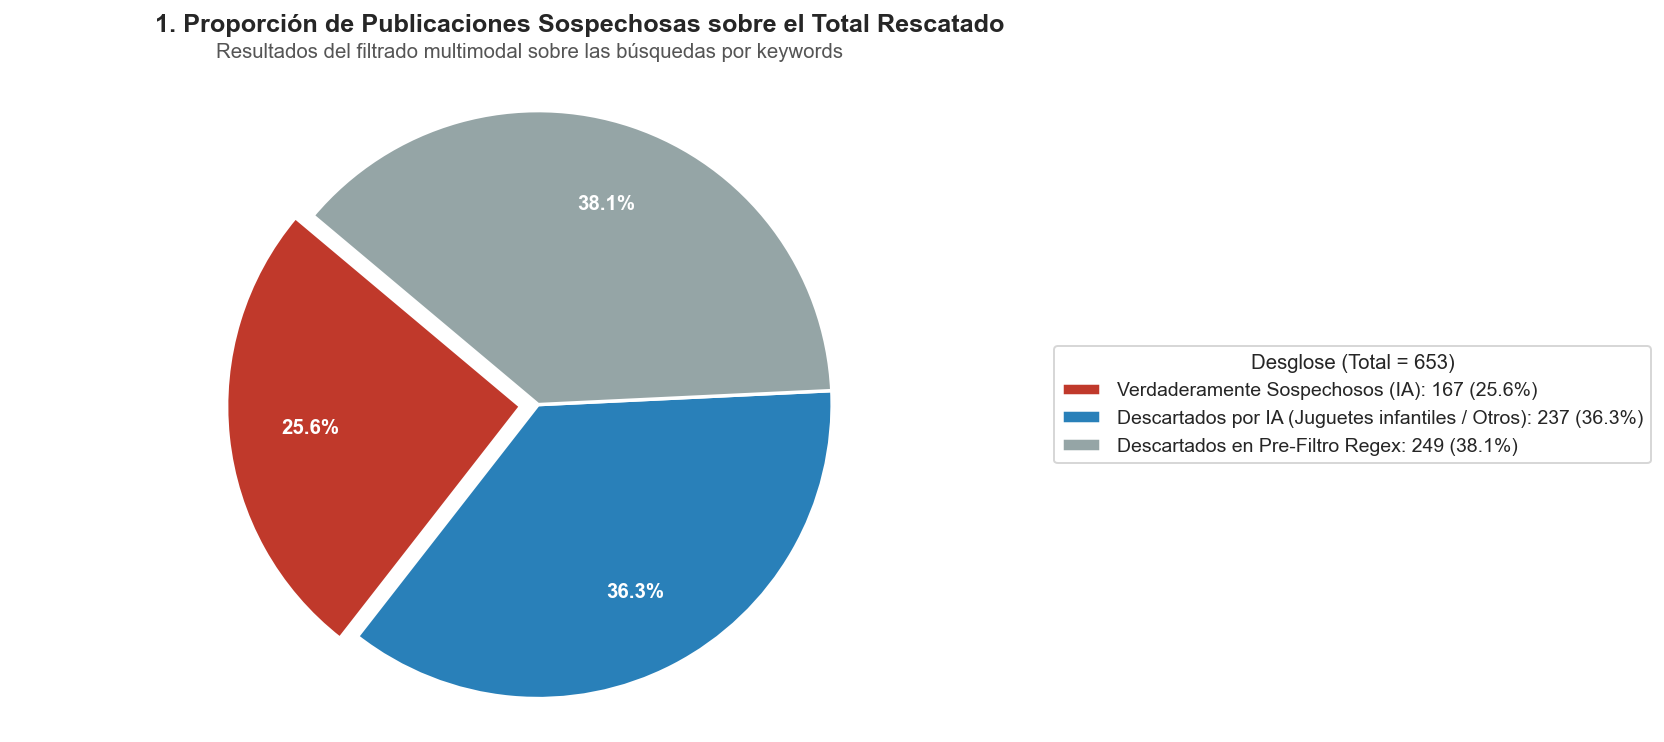

Guardado en: datos_marketplace/torta_1_proporcion_sospechosos.png



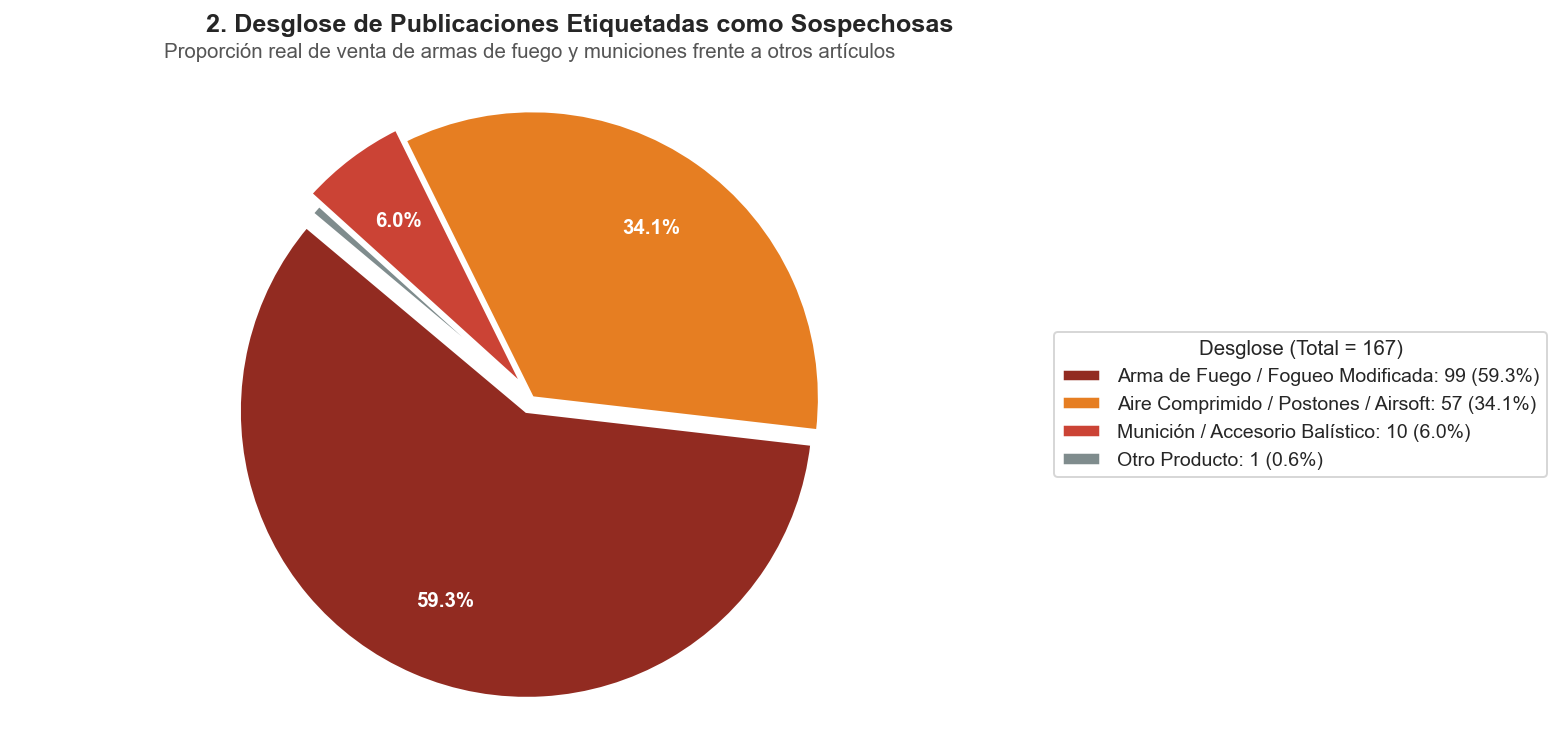

Guardado en: datos_marketplace/torta_2_desglose_armas_reales.png



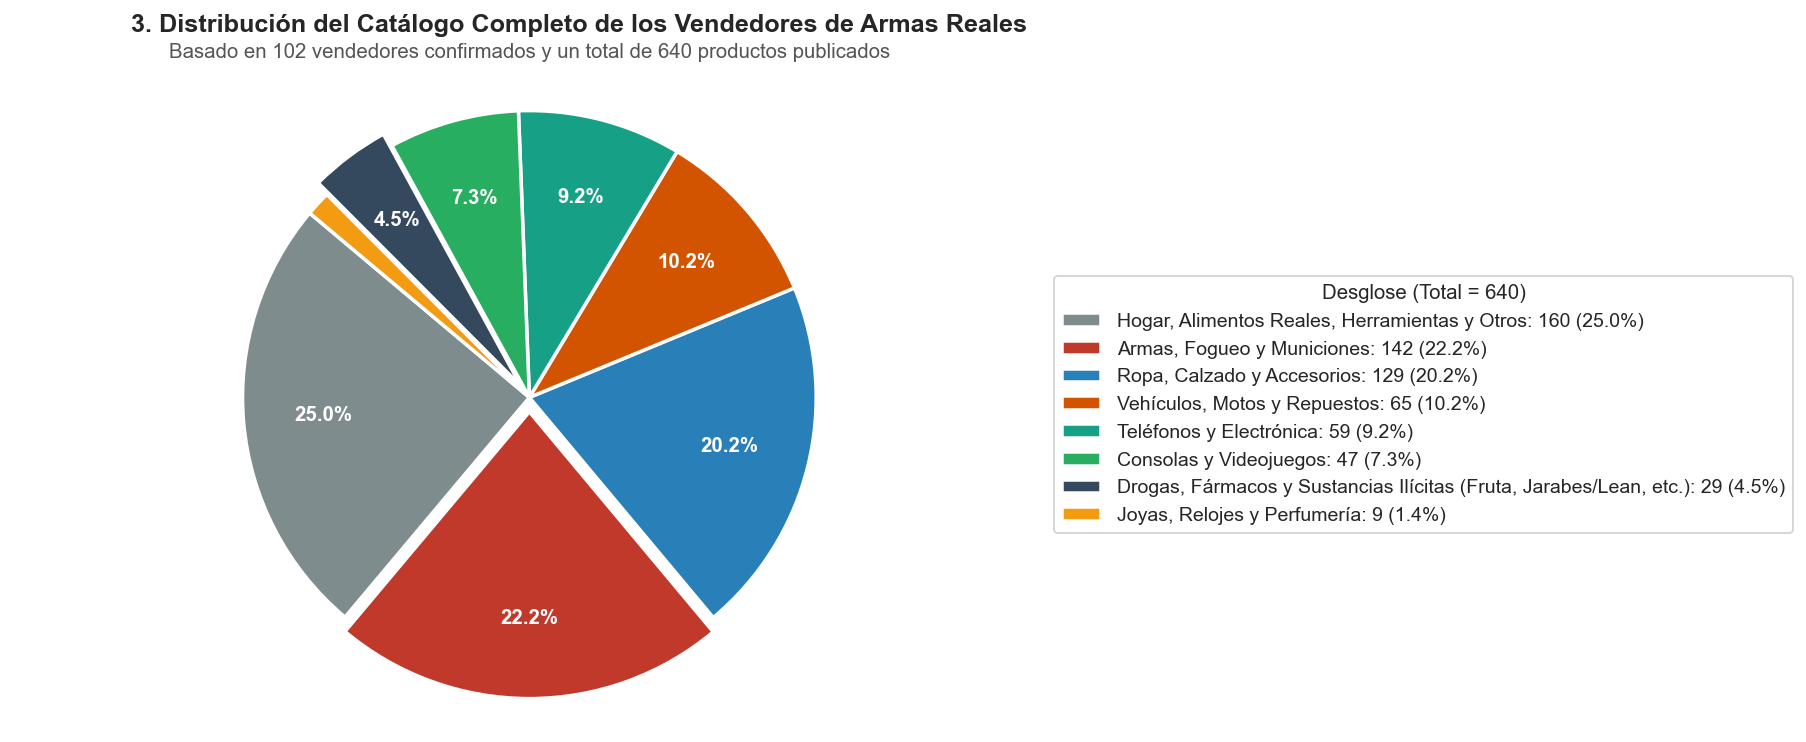

Guardado en: datos_marketplace/torta_3_catalogo_vendedores_armas.png



In [53]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 140

DATA_DIR = Path("datos_marketplace")

def cargar_jsonl(filepath: Path) -> pd.DataFrame:
    if not filepath.exists():
        return pd.DataFrame()
    with open(filepath, "r", encoding="utf-8") as f:
        return pd.DataFrame([json.loads(line) for line in f if line.strip()])

df_f1 = cargar_jsonl(DATA_DIR / "1_candidatos_busqueda.jsonl").drop_duplicates("listing_id")
df_e1 = cargar_jsonl(DATA_DIR / "4_auditoria_armas_etapa1.jsonl").drop_duplicates("listing_id")
df_e2 = cargar_jsonl(DATA_DIR / "5_productos_clasificados_etapa2.jsonl").drop_duplicates("item_id")

def graficar_torta_individual(serie_conteo: pd.Series, titulo: str, subtitulo: str, colores: list, nombre_archivo: str, explode=None):
    """Genera, muestra y guarda un gráfico de torta individual con leyenda detallada."""
    total = serie_conteo.sum()
    fig, ax = plt.subplots(figsize=(9.5, 6))
    
    # Mostrar % dentro de la torta solo si la tajada supera el 3.5% para evitar solapamientos
    def formato_pct(pct):
        return f"{pct:.1f}%" if pct >= 3.5 else ""

    wedges, texts, autotexts = ax.pie(
        serie_conteo.values,
        explode=explode,
        colors=colores,
        autopct=formato_pct,
        startangle=140,
        pctdistance=0.72,
        wedgeprops={"edgecolor": "white", "linewidth": 1.8},
        textprops={"fontsize": 10.5, "fontweight": "bold", "color": "white"}
    )
    
    # Etiquetas completas para la leyenda lateral (Categoría: N casos | X.X%)
    etiquetas_leyenda = [
        f"{nombre}: {valor:,} ({valor / total * 100:.1f}%)"
        for nombre, valor in zip(serie_conteo.index, serie_conteo.values)
    ]
    
    ax.legend(
        wedges,
        etiquetas_leyenda,
        title=f"Desglose (Total = {total:,})",
        title_fontsize=10.5,
        loc="center left",
        bbox_to_anchor=(1.0, 0.5),
        frameon=True,
        fontsize=10
    )
    
    plt.suptitle(titulo, fontweight="bold", fontsize=13, x=0.55, y=0.96)
    ax.set_title(subtitulo, fontsize=10.5, color="#555555", pad=12)
    ax.axis("equal")
    
    ruta_salida = DATA_DIR / nombre_archivo
    plt.savefig(ruta_salida, bbox_inches="tight", dpi=180)
    plt.show()
    print(f"Guardado en: {ruta_salida}\n")


# ==============================================================================
# GRÁFICO 1: Del Total de Publicaciones Rescatadas -> ¿Cuántas son Sospechosas?
# ==============================================================================
n_total_f1 = len(df_f1)
n_evaluados_ia = len(df_e1)
n_descartados_regex = max(0, n_total_f1 - n_evaluados_ia)

df_sospechosos = df_e1[df_e1["es_sospechoso_interes_estudio"] == True].copy()
n_sospechosos = len(df_sospechosos)
n_no_sospechosos_ia = n_evaluados_ia - n_sospechosos

serie_g1 = pd.Series({
    "Verdaderamente Sospechosos (IA)": n_sospechosos,
    "Descartados por IA (Juguetes infantiles / Otros)": n_no_sospechosos_ia,
    "Descartados en Pre-Filtro Regex": n_descartados_regex
})
# Si solo quieres graficar sobre los evaluados en Etapa 1 sin el pre-filtro Regex, 
# comenta la línea "Descartados en Pre-Filtro Regex" de arriba.
serie_g1 = serie_g1[serie_g1 > 0]

colores_g1 = ["#c0392b", "#2980b9", "#95a5a6"][:len(serie_g1)]
explode_g1 = [0.06] + [0.0] * (len(serie_g1) - 1)

graficar_torta_individual(
    serie_conteo=serie_g1,
    titulo="1. Proporción de Publicaciones Sospechosas sobre el Total Rescatado",
    subtitulo="Resultados del filtrado multimodal sobre las búsquedas por keywords",
    colores=colores_g1,
    nombre_archivo="torta_1_proporcion_sospechosos.png",
    explode=explode_g1
)


# ==============================================================================
# GRÁFICO 2: Dentro de las Sospechosas -> ¿Cuántas Vendían Realmente Armas?
# ==============================================================================
mapa_etiquetas_e1 = {
    "arma_fuego_o_fogueo_modificada": "Arma de Fuego / Fogueo Modificada",
    "municion_o_accesorio_balistico": "Munición / Accesorio Balístico",
    "arma_aire_comprimido_postones_airsoft": "Aire Comprimido / Postones / Airsoft",
    "droga_o_sustancia_ilicita_codificada": "Drogas / Sustancias Codificadas",
    "otro_producto_no_relacionado": "Otro Producto"
}

serie_g2 = (
    df_sospechosos["clasificacion_real"]
    .map(lambda x: mapa_etiquetas_e1.get(x, x))
    .value_counts()
)

paleta_g2 = {
    "Arma de Fuego / Fogueo Modificada": "#922b21",
    "Munición / Accesorio Balístico": "#cb4335",
    "Aire Comprimido / Postones / Airsoft": "#e67e22",
    "Drogas / Sustancias Codificadas": "#8e44ad",
    "Otro Producto": "#7f8c8d"
}
colores_g2 = [paleta_g2.get(cat, "#34495e") for cat in serie_g2.index]
explode_g2 = [0.05 if "Fuego" in cat or "Munición" in cat else 0.0 for cat in serie_g2.index]

graficar_torta_individual(
    serie_conteo=serie_g2,
    titulo="2. Desglose de Publicaciones Etiquetadas como Sospechosas",
    subtitulo="Proporción real de venta de armas de fuego y municiones frente a otros artículos",
    colores=colores_g2,
    nombre_archivo="torta_2_desglose_armas_reales.png",
    explode=explode_g2
)


# ==============================================================================
# GRÁFICO 3: Catálogo Completo de los Vendedores de Armas Reales
# ==============================================================================
CATEGORIAS_ARMA_REAL = [
    "arma_fuego_o_fogueo_modificada", 
    "municion_o_accesorio_balistico"
]
sellers_armas_reales = (
    df_sospechosos[df_sospechosos["clasificacion_real"].isin(CATEGORIAS_ARMA_REAL)]["seller_id"]
    .astype(str)
    .unique()
)

df_catalogo_armas = df_e2[df_e2["seller_id"].astype(str).isin(sellers_armas_reales)].copy()
serie_g3 = df_catalogo_armas["macro_categoria"].value_counts()

paleta_g3 = {
    "Armas, Fogueo y Municiones": "#c0392b",
    "Drogas, Fármacos y Sustancias Ilícitas": "#8e44ad",
    "Ropa, Calzado y Accesorios": "#2980b9",
    "Teléfonos y Electrónica": "#16a085",
    "Vehículos, Motos y Repuestos": "#d35400",
    "Joyas, Relojes y Perfumería": "#f39c12",
    "Consolas y Videojuegos": "#27ae60",
    "Hogar, Alimentos Reales, Herramientas y Otros": "#7f8c8d"
}
colores_g3 = [paleta_g3.get(cat, "#34495e") for cat in serie_g3.index]
explode_g3 = [0.05 if "Armas" in cat or "Drogas" in cat else 0.0 for cat in serie_g3.index]

graficar_torta_individual(
    serie_conteo=serie_g3,
    titulo="3. Distribución del Catálogo Completo de los Vendedores de Armas Reales",
    subtitulo=f"Basado en {len(sellers_armas_reales)} vendedores confirmados y un total de {len(df_catalogo_armas):,} productos publicados",
    colores=colores_g3,
    nombre_archivo="torta_3_catalogo_vendedores_armas.png",
    explode=explode_g3
)

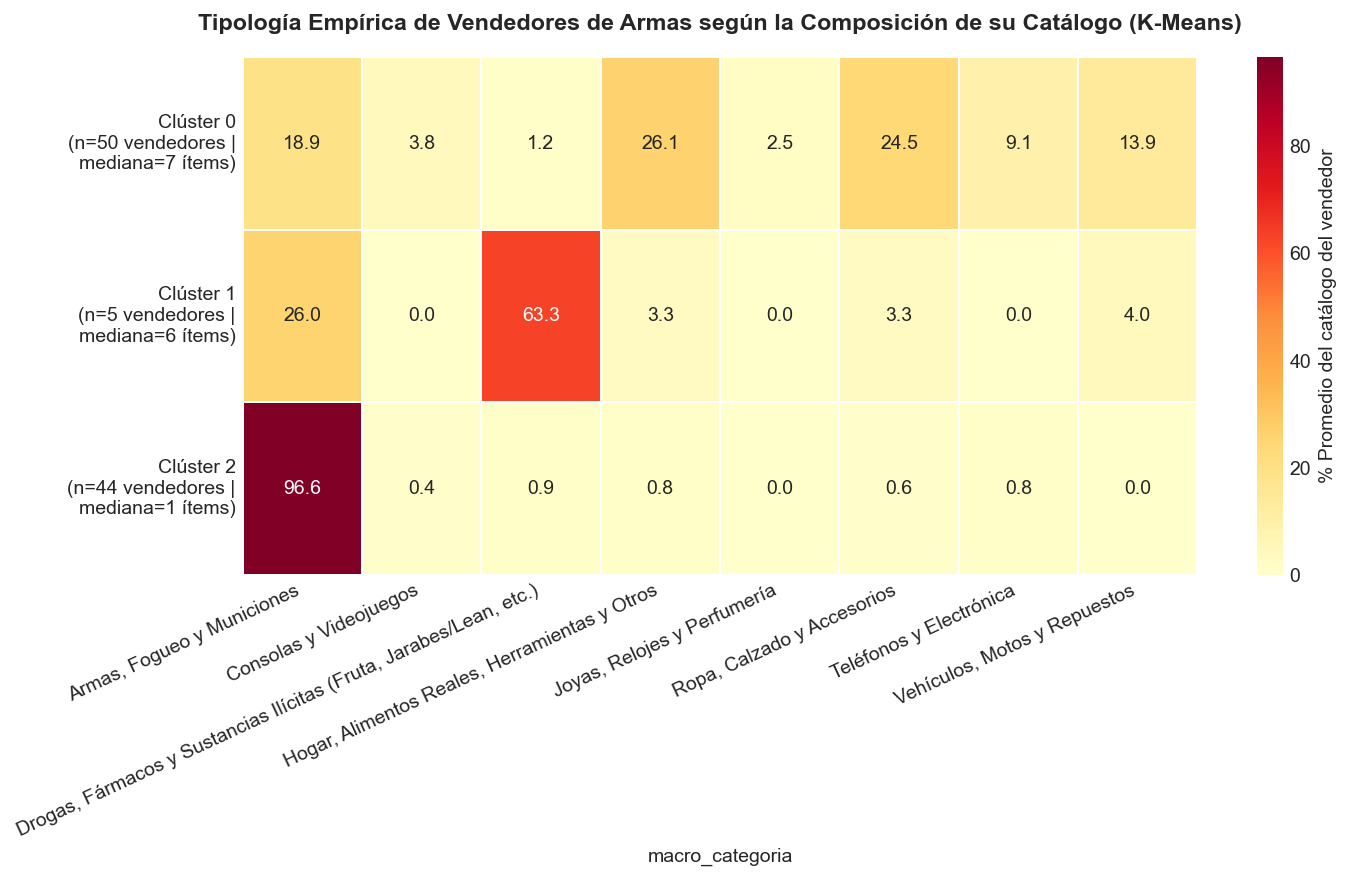

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Construir matriz Vendedor x Macro-Categoría (% de su catálogo en cada rubro)
matriz_prop = pd.crosstab(
    df_catalogo_armas["seller_id"],
    df_catalogo_armas["macro_categoria"],
    normalize="index"
) * 100

# 2. Estandarizar y aplicar K-Means (k=3 perfiles teóricos)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(matriz_prop)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=20)
matriz_prop["Cluster"] = kmeans.fit_predict(X_scaled)

# Agregar tamaño del catálogo por vendedor para caracterizar cada clúster
tamano_cat = df_catalogo_armas.groupby("seller_id")["item_id"].count()
matriz_prop["Total_Items"] = tamano_cat

# 3. Resumen promedio por Clúster (Centroides en porcentaje real)
columnas_rubros = [c for c in matriz_prop.columns if c not in ["Cluster", "Total_Items"]]
resumen_clusters = matriz_prop.groupby("Cluster")[columnas_rubros].mean().round(1)
conteo_vendedores_cluster = matriz_prop["Cluster"].value_counts()
mediana_items_cluster = matriz_prop.groupby("Cluster")["Total_Items"].median()

# Etiquetas descriptivas con el n de cada grupo
etiquetas_y = [
    f"Clúster {c}\n(n={conteo_vendedores_cluster[c]} vendedores |\nmediana={int(mediana_items_cluster[c])} ítems)"
    for c in resumen_clusters.index
]
resumen_clusters.index = etiquetas_y

# 4. Graficar Heatmap de Tipología de Vendedores
plt.figure(figsize=(11, 4.8))
sns.heatmap(
    resumen_clusters, 
    annot=True, 
    fmt=".1f", 
    cmap="YlOrRd", 
    cbar_kws={"label": "% Promedio del catálogo del vendedor"},
    linewidths=1
)
plt.title("Tipología Empírica de Vendedores de Armas según la Composición de su Catálogo (K-Means)", fontweight="bold", pad=14)
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.savefig(DATA_DIR / "grafico_2_clustering_vendedores.png", bbox_inches="tight")
plt.show()